# Model Training
Predicts whether each stock closes **higher tomorrow** using the features from
`feature_engineering.ipynb`. Run that notebook first.

Data is split **by date** (train on the past, test on the most recent 20%) so the
model never sees the future during training.

In [1]:
# Cell 1: Load features
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, classification_report)

DATA_DIR = '../data'
MODEL_DIR = '../models'
VIS_DIR = '../visualizations'
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(VIS_DIR, exist_ok=True)

df = pd.read_csv(f'{DATA_DIR}/features_all.csv', parse_dates=['Date'])
df = df.sort_values(['Date', 'ticker']).reset_index(drop=True)

print(f"✅ Loaded {len(df)} rows, {df['ticker'].nunique()} stocks")
print(f"   {df['Date'].min().date()} → {df['Date'].max().date()}")

✅ Loaded 2250 rows, 5 stocks
   2025-01-23 → 2026-11-05


In [2]:
# Cell 2: Choose features and split by date
# Exclude identifiers, the target, and raw price/volume levels (not comparable across stocks)
exclude = ['Date', 'ticker', 'target', 'next_day_return',
           'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume',
           'sma_5', 'sma_10', 'sma_20', 'sma_50',
           'MA_7', 'MA_21', 'MA_50', 'EMA_12', 'EMA_26',
           'BB_middle', 'BB_std', 'BB_upper', 'BB_lower', 'volume_MA_7']
feature_cols = [c for c in df.columns
                if c not in exclude and not c.startswith('target')]

# One-hot encode the ticker so one model can learn per-stock differences
X_all = pd.concat([df[feature_cols], pd.get_dummies(df['ticker'], prefix='tk', dtype=int)], axis=1)
y_all = df['target']

split_date = df['Date'].quantile(0.8)
train_mask = df['Date'] <= split_date
X_train, X_test = X_all[train_mask], X_all[~train_mask]
y_train, y_test = y_all[train_mask], y_all[~train_mask]

print(f"Features: {X_all.shape[1]}")
print(f"Train: {len(X_train)} rows (up to {split_date.date()})")
print(f"Test:  {len(X_test)} rows (after {split_date.date()})")
print(f"Up-day share in test set: {y_test.mean():.1%}")

Features: 41
Train: 1800 rows (up to 2026-06-30)
Test:  450 rows (after 2026-06-30)
Up-day share in test set: 50.9%


In [3]:
# Cell 3: Train models and compare
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1)),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20,
                                            random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=200, random_state=42),
}

# Baseline: always predict the most common class from training
majority = int(y_train.mean() >= 0.5)
results = [{
    'model': f'Baseline (always {"up" if majority else "down"})',
    'accuracy': accuracy_score(y_test, np.full(len(y_test), majority)),
    'precision': np.nan, 'recall': np.nan, 'f1': np.nan, 'roc_auc': 0.5,
}]

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = (pred, proba)
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_test, proba),
    })
    print(f"✅ Trained {name}")

results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

✅ Trained Logistic Regression


✅ Trained Random Forest
✅ Trained Gradient Boosting


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (always up),0.509,NaN,NaN,NaN,0.500
Logistic Regression,0.496,0.503,0.825,0.625,0.486
Random Forest,0.489,0.498,0.725,0.591,0.503
Gradient Boosting,0.502,0.508,0.686,0.584,0.521


In [4]:
# Cell 4: Detailed report for the best model (by ROC AUC)
best_name = results_df.drop(index=results_df.index[0])['roc_auc'].idxmax()
best_model = models[best_name]
best_pred, best_proba = predictions[best_name]

print(f"🏆 Best model: {best_name}\n")
print(classification_report(y_test, best_pred, target_names=['Down', 'Up'], zero_division=0))
print("Confusion matrix (rows = actual, cols = predicted):")
print(pd.DataFrame(confusion_matrix(y_test, best_pred),
                   index=['Actual Down', 'Actual Up'], columns=['Pred Down', 'Pred Up']))

🏆 Best model: Gradient Boosting

              precision    recall  f1-score   support

        Down       0.49      0.31      0.38       221
          Up       0.51      0.69      0.58       229

    accuracy                           0.50       450
   macro avg       0.50      0.50      0.48       450
weighted avg       0.50      0.50      0.48       450

Confusion matrix (rows = actual, cols = predicted):
             Pred Down  Pred Up
Actual Down         69      152
Actual Up           72      157


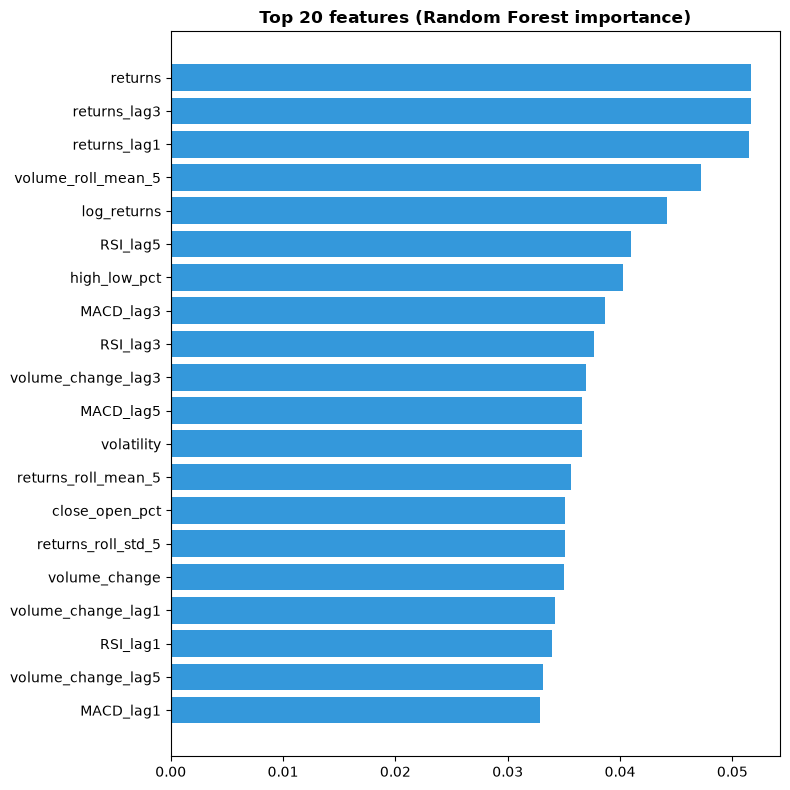

In [5]:
# Cell 5: Feature importance (Random Forest)
rf = models['Random Forest']
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(20)

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importance.index, importance.values, color='#3498db')
ax.set_title('Top 20 features (Random Forest importance)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{VIS_DIR}/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

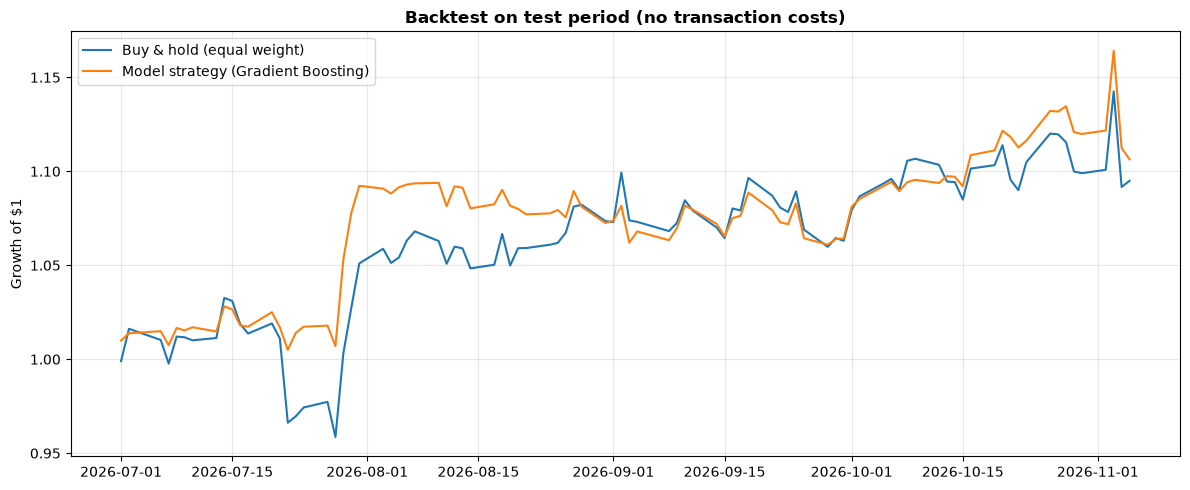

Buy & hold return: +9.50%
Strategy return:   +10.63%
Days in market:    68.7%


In [6]:
# Cell 6: Simple backtest on the test period
# Strategy: hold the stock tomorrow only when the model predicts "up"; otherwise stay in cash.
test = df.loc[~train_mask, ['Date', 'ticker', 'next_day_return']].copy()
test['signal'] = best_pred
test['strategy_return'] = test['signal'] * test['next_day_return']

# Equal-weight portfolio across stocks each day
daily = test.groupby('Date')[['next_day_return', 'strategy_return']].mean()
cumulative = (1 + daily).cumprod()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cumulative.index, cumulative['next_day_return'], label='Buy & hold (equal weight)')
ax.plot(cumulative.index, cumulative['strategy_return'], label=f'Model strategy ({best_name})')
ax.set_title('Backtest on test period (no transaction costs)', fontweight='bold')
ax.set_ylabel('Growth of $1')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{VIS_DIR}/backtest.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Buy & hold return: {cumulative['next_day_return'].iloc[-1] - 1:+.2%}")
print(f"Strategy return:   {cumulative['strategy_return'].iloc[-1] - 1:+.2%}")
print(f"Days in market:    {test['signal'].mean():.1%}")

In [7]:
# Cell 7: Retrain best model on all data and save it
final_model = models[best_name]
final_model.fit(X_all, y_all)

model_path = f'{MODEL_DIR}/best_model.joblib'
joblib.dump({'model': final_model, 'features': list(X_all.columns), 'name': best_name}, model_path)
print(f"✅ Saved {best_name} to {model_path}")

✅ Saved Gradient Boosting to ../models/best_model.joblib
